# 09 · Class imbalance

[Guide](../README.md) | [Previous](08_Outlier_Handling.ipynb) | [Next](10_Model_Comparison.ipynb)

## 1. What problem are we solving?

Does the mild excess of misses make goals harder to learn?

## 2. Why does it matter?

A model can favor the more common answer, but changing class counts can also increase false positives.

## 3. Key concepts

| Term | Simple meaning |
|---|---|
| Oversampling / undersampling | Repeat minority training rows / remove some majority training rows. |
| Class weights | Give some mistakes more influence during fitting; do not change the row count. |
| SMOTE | Create a numerical minority example between one minority row and a nearby minority row. |
| SMOTENC | A SMOTE extension for numerical and categorical inputs. Categories are chosen as categories, not averaged into invalid fractions. |
| Training-only sampling | Resample inside each fitting fold; leave validation/evaluation rows at their original proportions. |
| Pipeline notation | `clone` copies unfitted settings; `step__setting` changes one pipeline setting. Earlier steps stay fixed during a comparison. |

## 4. Intuitive example

Start with an illustrative 55 misses and 45 goals. Oversampling repeats 10 goals to reach 55/55; undersampling removes 10 misses to reach 45/45. Class weights keep all 100 rows but increase the influence of goal-class mistakes. None creates new observed penalties.

**Check:** The small numerical SMOTE demonstration later is **not** the same experiment as the full-feature balancing comparison. Do not transfer its winner to the complete pipeline.

## 5. Methods to compare

| Method | What changes | Trade-off |
|---|---|---|
| Original counts | Nothing | Simple; may favor the common class |
| Oversampling | Repeat minority training rows | Keeps information; repeated rows can overfit |
| Undersampling | Remove majority training rows | Faster; discards information |
| Class weights | Increase the cost of minority errors | Same rows; can increase false positives |
| SMOTE: separate numerical experiment | Interpolate minority neighbors | Invented points; unsuitable for averaging categories |

The full-input comparison chooses among the first four methods. Numerical-only SMOTE has its own matching baseline and does not replace that choice. SMOTENC is an explained alternative for mixed inputs. Resample fitting rows only.

## 6. What we retained from previous notebooks

| Earlier decision | Choice used here |
|---|---|
| Missing | Drop incomplete training rows |
| Scaling | Robust scaling |
| Encoding | One-hot |
| Features | All candidate groups |
| Selection | Drop suspected decoys + L1 |
| Reduction | No PCA |
| Outliers | Add a flag |

## 7. Setup

**Reusable setup — run this cell, then skip to the lesson.** You do not need to study all these lines now: they load the data and rebuild earlier steps so this notebook works on its own. Revisit the earlier lessons for explanations.

Change `DATA_DIR` for your runtime. The cell starts collapsed where the editor supports it; GitHub may show it expanded. `X` contains inputs; `y` contains known answers. Learned preparation stays inside training folds.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 3)

# Change this one folder on Kaggle or Colab (see the guide).
DATA_DIR = "../data"
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
print("Train:", train.shape, "Test:", test.shape)

# Split train.csv: 80% for training, 20% for a separate validation check.
training_data, validation_data = train_test_split(
    train, test_size=0.20, stratify=train["is_scored"], random_state=2026
)
training_data = training_data.reset_index(drop=True)

# IDs identify rows; they do not describe how a penalty was taken.
id_columns = ["id", "kicker_id", "keeper_id", "match_id"]
X = training_data.drop(columns=id_columns + ["is_scored"])
y = training_data["is_scored"]

from sklearn.base import clone
from sklearn.compose import make_column_selector
from sklearn.preprocessing import FunctionTransformer, RobustScaler
from sklearn.feature_selection import SelectFromModel
from imblearn import FunctionSampler
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline

def remove_incomplete_rows(X, y):
    keep = ~X.isna().any(axis=1)
    return X.loc[keep], y[keep]

def drop_suspected_decoys(data):
    return data.drop(columns=["jersey_color", "referee_strictness"], errors="ignore")

def add_relative_features(data):
    data = data.copy()
    data["skill_gap"] = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["foot_advantage"] = data["strong_foot_usage"] - data["weak_foot_usage"]
    data["form_ratio"] = (data["player_last5_scored_percent"] + 1) / (data["goalkeeper_last5_saved_percent"] + 1)
    data["form_interaction"] = data["player_last5_scored_percent"] * data["goalkeeper_last5_saved_percent"] / 100
    data["player_form_squared"] = (data["player_last5_scored_percent"] / 100) ** 2
    data["keeper_form_squared"] = (data["goalkeeper_last5_saved_percent"] / 100) ** 2
    return data

def add_pressure_features(data):
    data = data.copy()
    data["late_close_game"] = ((data["minute_taken"] >= 75) & (data["current_score_diff"].abs() <= 1)).astype(int)
    gap = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["skill_under_pressure"] = gap * data["late_close_game"]
    data["after_90_minutes"] = (data["minute_taken"] > 90).astype(int)
    data["trailing"] = (data["current_score_diff"] < 0).astype(int)
    data["tied_game"] = (data["current_score_diff"] == 0).astype(int)
    data["minute_score_interaction"] = data["minute_taken"] * data["current_score_diff"]
    data["crowd_support"] = (data["home_or_away"] == data["crowd_behind_goal"]).astype(int)
    data["late_final"] = ((data["minute_taken"] >= 75) & (data["match_type"] == "Final")).astype(int)
    return data

def add_environment_features(data):
    data = data.copy()
    data["poor_pitch"] = (data["pitch_condition"] == "Poor").astype(int)
    data["poor_pitch_late"] = data["poor_pitch"] * (data["minute_taken"] >= 75)
    data["humidity_weak_foot"] = data["weather_humidity"] / 100 * data["weak_foot_usage"]
    data["humidity_squared"] = (data["weather_humidity"] / 100) ** 2
    data["temperature_squared"] = data["temperature"] ** 2
    data["log_capacity"] = np.log1p(data["stadium_capacity"])
    return data

def add_features(data):
    data = add_relative_features(data)
    data = add_pressure_features(data)
    return add_environment_features(data)

def suspicious_rows(data):
    # Screening rules, not proof: unusual time, cold weather, or very large venue.
    return ((data["minute_taken"] > 120) |
            (data["temperature"] < 0) |
            (data["stadium_capacity"] > 110000))

def add_outlier_flag(data):
    data = data.copy()
    data["unusual_kick"] = suspicious_rows(data).astype(int)
    return data

numbers = Pipeline([("fill", SimpleImputer(strategy='median')), ("scale", RobustScaler())])
categories = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocess = ColumnTransformer([
    ("numbers", numbers, make_column_selector(dtype_include="number")),
    ("categories", categories, make_column_selector(dtype_exclude="number")),
])

pipeline = Pipeline([
    ("missing_rows", FunctionSampler(func=remove_incomplete_rows, validate=False)),
    ("outlier_values", FunctionTransformer(add_outlier_flag)),
    ("features", FunctionTransformer(add_features)),
    ("decoys", FunctionTransformer(drop_suspected_decoys)),
    ("prepare", preprocess),
    ("selection", SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", max_iter=1000, random_state=42))),
    ("balance", "passthrough"),
    ("model", LogisticRegression(solver="liblinear", max_iter=1000, random_state=42)),
])

# Each fold trains on two parts and predicts the third, unseen part.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def compare(models, X, y):
    rows = []
    for name, model in models.items():
        scores = cross_validate(model, X, y, cv=cv, scoring=["f1", "accuracy", "roc_auc"])
        rows.append([name, scores["test_f1"].mean(), scores["test_f1"].std(),
                     scores["test_accuracy"].mean(), scores["test_roc_auc"].mean()])
    columns = ["method", "F1", "F1 spread", "accuracy", "ROC-AUC"]
    return pd.DataFrame(rows, columns=columns).sort_values("F1", ascending=False)

Train: (20000, 20) Test: (6000, 19)


## 8. Experiments

Run the topic-specific steps below. Saved experimental outputs are retained from the earlier runs; regrouping setup does not create a new evaluation.

In [17]:
display(y.value_counts().sort_index().rename(index={0: "Missed", 1: "Scored"}))

is_scored
Missed    8799
Scored    7201
Name: count, dtype: int64

In [18]:
models = {
    "Original class counts": clone(pipeline),
    "Random oversampling": clone(pipeline).set_params(balance=RandomOverSampler(random_state=42)),
    "Random undersampling": clone(pipeline).set_params(balance=RandomUnderSampler(random_state=42)),
    "Class weights": clone(pipeline).set_params(model__class_weight="balanced"),
}

,method,F1,F1 spread,accuracy,ROC-AUC
0,Original class counts,0.899,0.002,0.910,0.967
1,Random oversampling,0.898,0.002,0.907,0.967
3,Class weights,0.898,0.002,0.907,0.967
2,Random undersampling,0.897,0.002,0.907,0.967


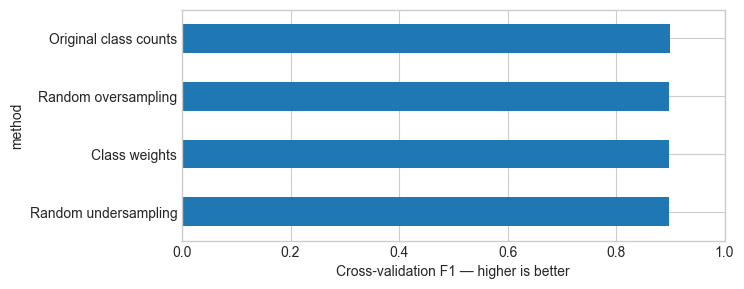

Continue with: Original class counts


In [19]:
results = compare(models, X, y)
display(results.round(4))
results.set_index("method")["F1"].sort_values().plot.barh(figsize=(7, 3))
plt.xlabel("Cross-validation F1 — higher is better")
plt.xlim(0, 1)
plt.show()
print("Continue with:", results.iloc[0]["method"])

**Continue with the winning full-input strategy above.** The same rule is used in model comparison.

### Extra experiment: SMOTE
SMOTE makes points between minority neighbors. It cannot average text categories meaningfully.
This small comparison therefore uses the same numerical inputs for both methods; its winner does
not replace the full-input choice above. SMOTENC is the appropriate extension for mixed feature types.

### Before SMOTE: one synthetic point, not a copied penalty

Illustrative numerical neighbors: `A=[30, 20]`, `B=[70, 40]`.
At halfway, `S = A + 0.5 × (B − A) = [50, 30]`; give S the minority label.
SMOTE chooses nearby minority neighbors and interpolation fractions, not necessarily the halfway point. Scaling affects which rows are neighbors.

The point is invented, not another observed goal. Never average Home and Away into a fractional category: use SMOTENC for mixed feature types. The scored SMOTE experiment below uses numerical inputs only, with a matching numerical baseline.

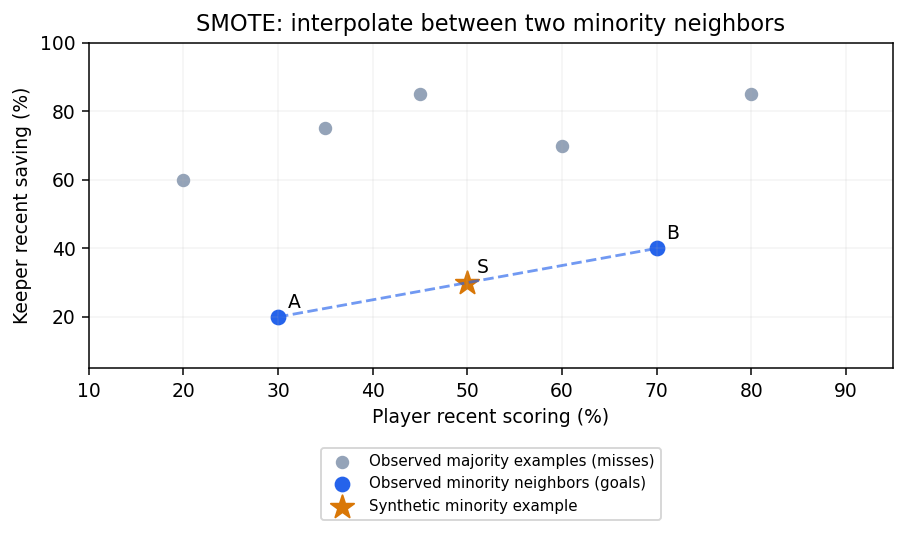

In [20]:
from imblearn.over_sampling import SMOTE
numeric_X = X.select_dtypes(include="number")
plain = Pipeline([
    ("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
    ("balance", "passthrough"), ("model", LogisticRegression(max_iter=1000)),
])
numeric_models = {
    "No balancing": plain,
    "SMOTE": clone(plain).set_params(balance=SMOTE(random_state=42)),
}
display(compare(numeric_models, numeric_X, y).round(4))

,method,F1,F1 spread,accuracy,ROC-AUC
1,SMOTE,0.703,0.004,0.726,0.801
0,No balancing,0.691,0.006,0.731,0.802


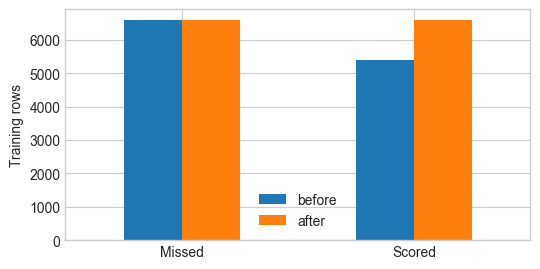

In [21]:
X_fit, X_example, y_fit, y_example = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
repeated_X, repeated_y = RandomOverSampler(random_state=42).fit_resample(X_fit, y_fit)
counts = pd.DataFrame({"before": y_fit.value_counts().sort_index(), "after": repeated_y.value_counts().sort_index()})
counts.index = ["Missed", "Scored"]
counts.plot.bar(rot=0, figsize=(6, 3))
plt.ylabel("Training rows")
plt.show()

**Other alternatives:** ADASYN generates near difficult examples (may amplify noise);
BorderlineSMOTE focuses on boundaries; Tomek links remove conflicting neighbors;
SMOTE–ENN combines synthesis and cleanup (may remove useful boundary cases).
Always sample training rows only; evaluation retains the original class proportions.

## 9. Results and decision

| Question | Answer |
|---|---|
| What did we compare? | Original counts, oversampling, undersampling, and class weights; separately compare numerical-only SMOTE with no balancing. |
| Which performed best? | Original class counts — mean CV F1 0.8990 (rounded saved result). |
| Why did we choose it? | The mild 55/45 imbalance did not justify changing the training distribution in the full-input comparison. |
| What are its limitations? | Minority errors may remain. Numerical-only SMOTE is a separate experiment and cannot replace the full-input comparison's winner. |
| What continues to the next notebook? | Original class counts; do not carry the numerical-only SMOTE result into the full-input pipeline. |

## 10. Key takeaways and next step

- Balancing changes training emphasis, not the information in the observed labels.
- SMOTE needs appropriate numerical distances; mixed categories require a suitable alternative.

Next: [10 Model Comparison](10_Model_Comparison.ipynb).